# 🔎 Tabu Search for Feature Selection
**Project 10 — Recherche tabou pour la sélection de variables**

**Goal:** explore the space of feature subsets with tabu search (swap/flip neighbourhood, tabu list, aspiration criterion), compare it with a Genetic Algorithm (GA) and Simulated Annealing (SA), and analyse the effect of the **tabu list size / tenure**.

**Dataset:** Breast Cancer Wisconsin (30 features) · **Model:** Logistic Regression · **Fitness:** 5-fold CV error + λ · (selected features / total features)

| Part | Content |
|---|---|
| 1 | Setup |
| 2 | Data loading & exploration |
| 3 | Preprocessing (split + scaling) |
| 4 | Fitness function |
| 5 | Tabu search (neighbourhood, algorithm, run) |
| 6 | Tabu search results |
| 7 | Tenure & tabu list size analysis |
| 8 | Genetic Algorithm |
| 9 | Simulated Annealing |
| 10 | Second dataset (Spambase) |

# 1. Setup
### Libraries and plotting configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

%matplotlib inline

# 2. Data Loading & Exploration
### 2.1 Load the Breast Cancer Wisconsin CSV

In [2]:
df_bc=pd.read_csv("data.csv")

### 2.2 Preview the raw table

In [3]:
df_bc

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


### 2.3 Shape, data types and class balance

In [4]:
print(df_bc.shape)
print(df_bc.head())
print('data types: ',df_bc.dtypes.value_counts())
print(df_bc['diagnosis'].value_counts())

(569, 33)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  

### 2.4 Data quality: missing values and duplicates

In [5]:
print('missing values: ',df_bc.isnull().sum())
print('duplicates: ',df_bc.duplicated().sum())




missing values:  id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_wors

### 2.5 Build the feature matrix `x` and target `y`  (M = 1 malignant, B = 0 benign)

In [6]:

x = df_bc.drop(columns=['id', 'diagnosis', 'Unnamed: 32'])
y = (df_bc['diagnosis'] == 'M').astype(int)   # M = 1 (malignant), B = 0 (benign)

print(x.shape)          
print(y.value_counts())

(569, 30)
diagnosis
0    357
1    212
Name: count, dtype: int64


# 3. Preprocessing
### 3.1 Stratified train / test split (80 % / 20 %)
The test set is kept untouched until the very end.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, stratify=y, random_state=42)

### 3.2 Standardise the features (scaler fitted on the training set only)

In [8]:
scaler = StandardScaler().fit(X_train)
feature_names = list(x.columns)

X_train = scaler.transform(X_train)   # numpy arrays from now on: columns are picked by index

X_test  = scaler.transform(X_test)
y_train, y_test = y_train.to_numpy(),y_test.to_numpy()

n_features = X_train.shape[1]         # 30
print(X_train.shape, X_test.shape)   # (455, 30) (114, 30)
print(n_features, X_train.mean().round(3), X_train.std().round(3))


(455, 30) (114, 30)
30 0.0 1.0


# 4. Fitness Function
### Minimisation objective = classification error (5-fold CV) + λ · k / n
Balances accuracy against the number of selected features `k` (out of `n`).

In [9]:

from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

def make_fitness(X_train, y_train, lam=0.1, k_neighbors=5):
    n = X_train.shape[1]

    def error_rate(s):
        cols = np.where(s == 1)[0]
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        return 1 - cross_val_score(model, X_train[:, cols], y_train, cv=5).mean()

    def fitness(s):
        if s.sum() == 0:
            return np.inf
        return error_rate(s) + lam * s.sum() / n

    return fitness, error_rate

fitness, error_rate = make_fitness(X_train, y_train, lam=0.1, k_neighbors=5)

# 5. Tabu Search
### 5.1 Neighbourhood: flip one feature (add / remove) at a time

In [10]:
# ---- 7. Swap neighborhood: 
def neighbors(s):
    for i in range(len(s)):
        s_new = s.copy()
        s_new[i] = 1 - s_new[i]
        yield s_new, i

### 5.2 Tabu search algorithm
Tabu list with a **tenure**, aspiration criterion (a tabu move is allowed if it beats the best solution so far), and full history tracking.

In [11]:
# ---- 9. Tabu search (flip version) ----
def tabu_search(fitness, s_init, tenure=5, max_iter=30):
    n = len(s_init)
    s = s_init.copy()
    f_s = fitness(s)
    best_s, best_f = s.copy(), f_s

    tabu_until = np.zeros(n, dtype=int)
    history, best_history = [f_s], [best_f]
    feature_count_history, move_history = [int(s.sum())], []

    for it in range(1, max_iter + 1):
        chosen, chosen_f, chosen_move = None, np.inf, None

        for s_new, i in neighbors(s):                 # CHANGE 1: one index only
            f_new = fitness(s_new)
            is_tabu = tabu_until[i] >= it             # CHANGE 2: only i
            aspiration = f_new < best_f
            if is_tabu and not aspiration:
                continue
            if f_new < chosen_f:
                chosen, chosen_f, chosen_move = s_new, f_new, i

        if chosen is None:
            break

        s, f_s = chosen, chosen_f
        i = chosen_move
        tabu_until[i] = it + tenure                   # freeze only feature i

        if f_s < best_f:
            best_s, best_f = s.copy(), f_s

        history.append(f_s)
        best_history.append(best_f)
        feature_count_history.append(int(s.sum()))
        action = "add" if s[i] == 1 else "remove"
        move_history.append((i, action))     # CHANGE 3: new print line
        print(f"it {it:2d} | {action:<6s} {feature_names[i]:<24s} | f={f_s:.4f} | best={best_f:.4f} | k={s.sum()}")

    return best_s, best_f, history, best_history, feature_count_history, move_history


### 5.3 Run tabu search (starting from the empty subset, tenure = 5)

it  1 | add    perimeter_worst          | f=0.0803 | best=0.0803 | k=1
it  2 | add    smoothness_worst         | f=0.0506 | best=0.0506 | k=2
it  3 | add    texture_mean             | f=0.0408 | best=0.0408 | k=3
it  4 | add    symmetry_mean            | f=0.0397 | best=0.0397 | k=4
it  5 | add    concave points_se        | f=0.0408 | best=0.0397 | k=5
it  6 | add    smoothness_mean          | f=0.0420 | best=0.0397 | k=6
it  7 | add    compactness_mean         | f=0.0453 | best=0.0397 | k=7
it  8 | add    concavity_mean           | f=0.0508 | best=0.0397 | k=8
it  9 | add    texture_se               | f=0.0520 | best=0.0397 | k=9
it 10 | add    area_se                  | f=0.0553 | best=0.0397 | k=10
it 11 | remove concave points_se        | f=0.0520 | best=0.0397 | k=9
it 12 | remove smoothness_mean          | f=0.0486 | best=0.0397 | k=8
it 13 | remove symmetry_mean            | f=0.0453 | best=0.0397 | k=7
it 14 | remove compactness_mean         | f=0.0464 | best=0.0397 | k=6
it 15

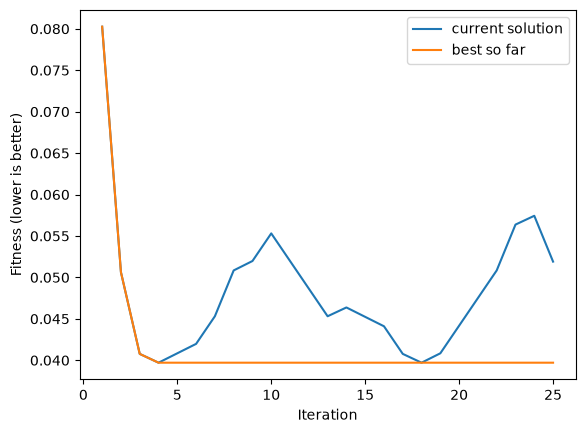

In [12]:
# Reproducible initial solution
rng = np.random.default_rng(42)
s0 = rng.integers(0, 2, size=X_train.shape[1])
s0=np.array([0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0])
best_s, best_f, hist, best_hist, feature_count_history, move_history = tabu_search(fitness, s0, tenure=5, max_iter=25)

print("Best fitness:", round(best_f, 4), "| selected features:", int(best_s.sum()))
print([feature_names[i] for i in np.where(best_s == 1)[0]])

plt.plot(hist, label="current solution")
plt.plot(best_hist, label="best so far")
plt.xlabel("Iteration")
plt.ylabel("Fitness (lower is better)")
plt.legend()
plt.show()


# 6. Tabu Search Results
### 6.1 Search trajectory

### Tabu search result plots
These plots summarize the search trajectory and compare the final selected-feature model with an all-feature logistic-regression baseline. The saved `stats` table and these evaluation definitions can be reused for other feature-selection algorithms on the same fixed split.

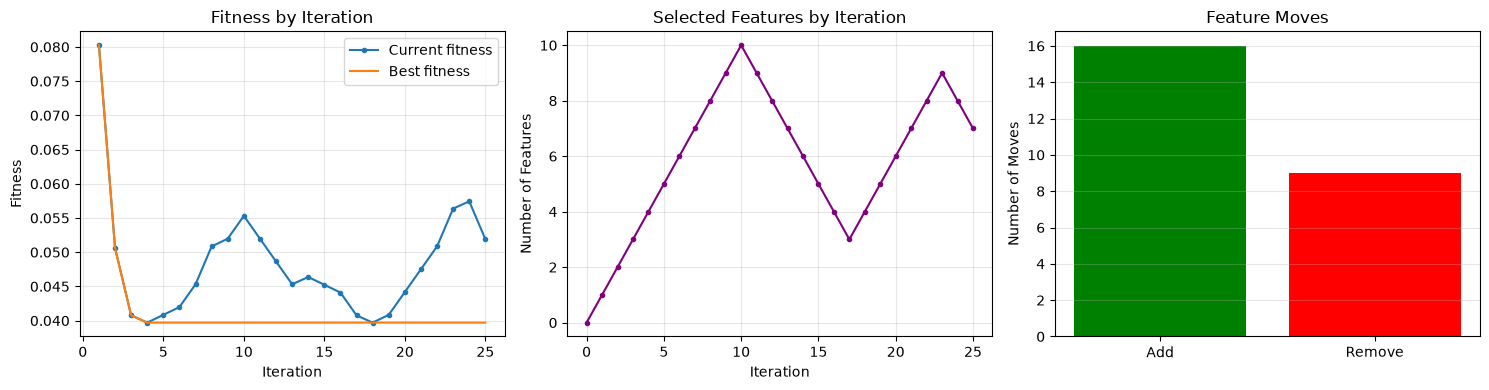

In [13]:

# ---- Tabu Search Statistics ----

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Fitness by iteration
axes[0].plot(hist, label="Current fitness", marker="o", ms=3)
axes[0].plot(best_hist, label="Best fitness")
axes[0].set_title("Fitness by Iteration")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Fitness")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. Number of selected features
axes[1].plot(feature_count_history, color="purple", marker="o", ms=3)
axes[1].set_title("Selected Features by Iteration")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Number of Features")
axes[1].grid(alpha=0.3)

# 3. Feature moves
moves = pd.Series([action for _, action in move_history]).value_counts()

axes[2].bar(
    ["Add", "Remove"],
    [moves.get("add", 0), moves.get("remove", 0)],
    color=["green", "red"]
)
axes[2].set_title("Feature Moves")
axes[2].set_ylabel("Number of Moves")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### 6.2 Final statistics of the selected subset (CV error, test accuracy, test F1)

In [14]:

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Selected features
selected_idx = np.flatnonzero(best_s)

if len(selected_idx) == 0:
    raise ValueError("No features selected.")

# Train model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

model.fit(X_train[:, selected_idx], y_train)

# Evaluate on test set
pred = model.predict(X_test[:, selected_idx])

# Collect essential statistics
tabu_stats = {
    "Algorithm": "Tabu Search",
    "Features": len(selected_idx),
    "CV Error": error_rate(best_s),
    "Test Accuracy": accuracy_score(y_test, pred),
    "Test F1": f1_score(y_test, pred)
}

print(pd.DataFrame([tabu_stats]))
print("Selected features:", selected_idx)


     Algorithm  Features  CV Error  Test Accuracy  Test F1
0  Tabu Search         4  0.026374       0.982456  0.97561
Selected features: [ 1  8 22 24]


### 6.3 Cross-validated accuracy of the selected subset

In [15]:

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

scores = cross_val_score(
    model,
    X_train[:, selected_idx],
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("CV Accuracy:", scores.mean())


CV Accuracy: 0.9736263736263737


# 7. Tenure & Tabu List Size Analysis
The tenure controls how many iterations a feature stays frozen after being flipped. Since each move freezes exactly one feature, **the tabu list size is governed by the tenure**: at most `tenure` features are tabu at the same time.

- **Small tenure** → little memory, the search can cycle (flip a feature, flip it back).
- **Large tenure** → strong diversification, but good moves may stay blocked.

**Protocol:** run the same tabu search (`max_iter = 25`) for several tenures, from 4 different starting subsets (empty + 3 random), and compare the final fitness, subset size, convergence speed and cycling behaviour.

### 7.1 Run the experiment

In [16]:
import io, time
from collections import Counter
from contextlib import redirect_stdout

# ---- Experiment settings ----
tenures    = [1, 2, 3, 5, 8, 12, 20]          # tenure values to compare
max_iter_t = 25                               # same budget as the main run
start_points = {"empty": np.zeros(n_features, dtype=int)}
for seed in (0, 1, 2):                        # + 3 random starting subsets
    start_points[f"random_{seed}"] = np.random.default_rng(seed).integers(0, 2, size=n_features)

# cache: the same subset is never evaluated twice (neighbourhoods overlap a lot between runs)
_cache = {}
def fitness_cached(s):
    key = s.tobytes()
    if key not in _cache:
        _cache[key] = fitness(s)
    return _cache[key]

# ---- Run tabu search for every (tenure, start) pair ----
rows, curves, moves_log = [], {t: [] for t in tenures}, {}
for t in tenures:
    for name, s_start in start_points.items():
        t0 = time.time()
        with redirect_stdout(io.StringIO()):          # silence the per-iteration prints
            b_s, b_f, h, bh, fc, mh = tabu_search(fitness_cached, s_start, tenure=t, max_iter=max_iter_t)
        counts = Counter(i for i, _ in mh)
        rows.append({
            "tenure": t,
            "start": name,
            "best_fitness": b_f,
            "n_features": int(b_s.sum()),
            "iter_of_best": int(np.argmax(np.array(bh) == b_f)),
            "iterations_done": len(mh),
            "distinct_features_moved": len(counts),
            "max_moves_same_feature": max(counts.values()) if counts else 0,
            "time_s": time.time() - t0,
        })
        curves[t].append(bh + [bh[-1]] * (max_iter_t + 1 - len(bh)))   # pad if search stopped early
        moves_log[(t, name)] = mh

df_tenure = pd.DataFrame(rows)
df_tenure.head(8)

,tenure,start,best_fitness,n_features,iter_of_best,iterations_done,distinct_features_moved,max_moves_same_feature,time_s
0,1,empty,0.039707,4,4,25,6,8,33.383635
1,1,random_0,0.039707,4,16,25,16,6,81.792031
2,1,random_1,0.039707,4,11,25,13,7,53.761426
3,1,random_2,0.041978,6,10,25,10,9,40.005633
4,2,empty,0.039707,4,4,25,6,8,0.005563
5,2,random_0,0.038645,5,23,25,21,3,16.277011
6,2,random_1,0.037509,4,19,25,17,3,26.185914
7,2,random_2,0.041978,6,10,25,11,7,7.930135


### 7.2 Statistics per tenure
Mean / std / min of the best fitness, subset size, iteration where the best was found, and cycling indicators.

In [17]:
summary = df_tenure.groupby("tenure").agg(
    mean_best_fitness=("best_fitness", "mean"),
    std_best_fitness=("best_fitness", "std"),
    min_best_fitness=("best_fitness", "min"),
    mean_n_features=("n_features", "mean"),
    mean_iter_of_best=("iter_of_best", "mean"),
    mean_iterations_done=("iterations_done", "mean"),
    mean_distinct_features_moved=("distinct_features_moved", "mean"),
    mean_max_moves_same_feature=("max_moves_same_feature", "mean"),
).round(4)

display(summary)
print("Best tenure (lowest mean best fitness):", summary["mean_best_fitness"].idxmin())

,mean_best_fitness,std_best_fitness,min_best_fitness,mean_n_features,mean_iter_of_best,mean_iterations_done,mean_distinct_features_moved,mean_max_moves_same_feature
tenure,,,,,,,,
1,0.0403,0.0011,0.0397,4.50,10.25,25.0,11.25,7.50
2,0.0395,0.0019,0.0375,4.75,14.00,25.0,13.75,5.25
3,0.0395,0.0019,0.0375,4.75,14.00,25.0,14.50,4.25
5,0.0397,0.0018,0.0375,4.50,12.75,25.0,16.75,3.25
8,0.0395,0.0019,0.0376,5.25,16.50,25.0,18.50,2.50
12,0.0397,0.0016,0.0386,5.00,12.75,25.0,19.50,2.00
20,0.0400,0.0014,0.0386,4.75,11.00,25.0,23.50,2.00


Best tenure (lowest mean best fitness): 2


### 7.3 Plots: quality, subset size, convergence and cycling

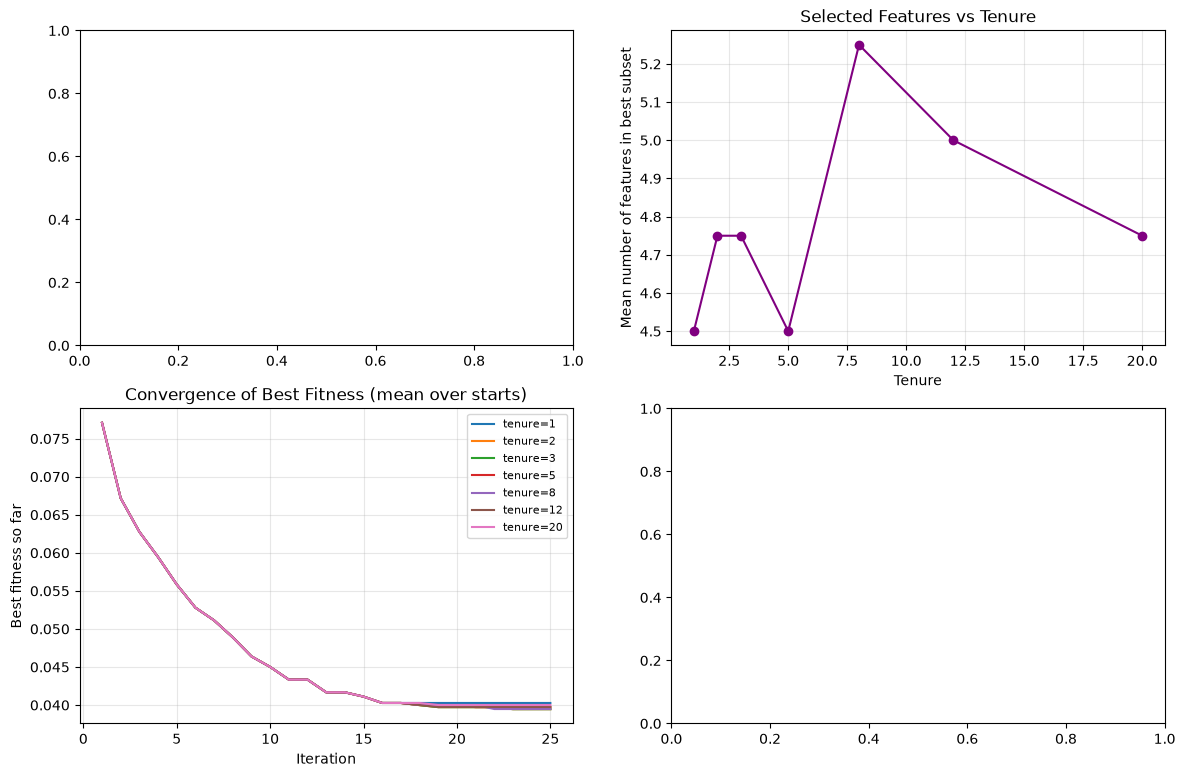

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))



# 2. Subset size vs tenure
axes[0, 1].plot(summary.index, summary["mean_n_features"], color="purple", marker="o")
axes[0, 1].set_title("Selected Features vs Tenure")
axes[0, 1].set_xlabel("Tenure")
axes[0, 1].set_ylabel("Mean number of features in best subset")
axes[0, 1].grid(alpha=0.3)

# 3. Convergence curves (mean over starts)
for t in tenures:
    axes[1, 0].plot(np.mean(curves[t], axis=0), label=f"tenure={t}")
axes[1, 0].set_title("Convergence of Best Fitness (mean over starts)")
axes[1, 0].set_xlabel("Iteration")
axes[1, 0].set_ylabel("Best fitness so far")
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(alpha=0.3)
plt.show()

### 7.4 Tabu list size over the iterations
Number of frozen features at each iteration for every tenure (empty start): it grows until it saturates at the tenure value.

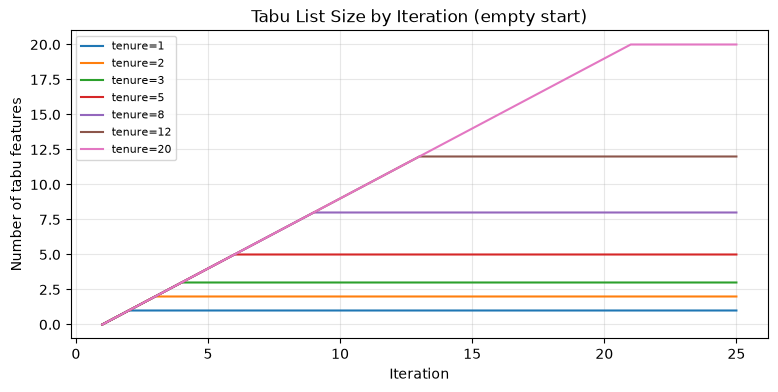

In [19]:
def tabu_list_size(move_history, tenure):
    """Number of tabu (frozen) features at each iteration, rebuilt from the move history."""
    last_move, sizes = {}, []
    for it, (i, _) in enumerate(move_history, start=1):
        sizes.append(sum(1 for it_j in last_move.values() if it_j + tenure >= it))
        last_move[i] = it
    return sizes

plt.figure(figsize=(9, 4))
for t in tenures:
    plt.plot(range(1, len(moves_log[(t, "empty")]) + 1),
             tabu_list_size(moves_log[(t, "empty")], t), label=f"tenure={t}")
plt.title("Tabu List Size by Iteration (empty start)")
plt.xlabel("Iteration")
plt.ylabel("Number of tabu features")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

# 8. Genetic Algorithm
### 8.1 GA implementation (tournament selection, uniform crossover, bit-flip mutation, elitism)

In [20]:
import numpy as np

def genetic_algorithm(fitness, n, pop_size=30, generations=50,
                      p_cx=0.9, p_mut=None, tourn_k=3, elite=2, seed=0):
    rng = np.random.default_rng(seed)
    p_mut = p_mut if p_mut is not None else 1.0 / n   # ~1 flip per child on average
    cache = {}                                        # avoid re-evaluating same mask
    n_evals = 0

    def evaluate(ind):
        nonlocal n_evals
        key = ind.tobytes()
        if key not in cache:
            cache[key] = fitness(ind)
            n_evals += 1
        return cache[key]

    # init: random masks, make sure at least 1 feature selected
    pop = rng.integers(0, 2, size=(pop_size, n))
    for ind in pop:
        if ind.sum() == 0:
            ind[rng.integers(n)] = 1

    best, best_f = None, np.inf
    hist_best, hist_mean, hist_evals = [], [], []

    for g in range(generations):
        fit = np.array([evaluate(ind) for ind in pop])

        i = fit.argmin()
        if fit[i] < best_f:
            best_f, best = fit[i], pop[i].copy()
        hist_best.append(best_f); hist_mean.append(fit.mean()); hist_evals.append(n_evals)

        # elitism: keep the best `elite` individuals
        order = np.argsort(fit)
        new_pop = [pop[j].copy() for j in order[:elite]]

        # tournament selection
        def select():
            idx = rng.integers(0, pop_size, size=tourn_k)
            return pop[idx[fit[idx].argmin()]]

        while len(new_pop) < pop_size:
            p1, p2 = select(), select()
            # uniform crossover
            if rng.random() < p_cx:
                m = rng.random(n) < 0.5
                c1, c2 = np.where(m, p1, p2), np.where(m, p2, p1)
            else:
                c1, c2 = p1.copy(), p2.copy()
            # bit-flip mutation
            for c in (c1, c2):
                flip = rng.random(n) < p_mut
                c[flip] = 1 - c[flip]
                if c.sum() == 0:
                    c[rng.integers(n)] = 1
                new_pop.append(c)
        pop = np.array(new_pop[:pop_size])

    return best, best_f, hist_best, hist_mean, hist_evals

### 8.2 Run the GA

In [21]:
best, best_f, hb, hm, he = genetic_algorithm(fitness, n=X_train.shape[1])
print(best_f, best.sum())
# evaluate on the test set once, at the end, like with tabu

0.039706959706959616 4


# 9. Simulated Annealing
### 9.1 SA implementation (single bit-flip neighbour, geometric cooling)

In [22]:
import numpy as np

def simulated_annealing(fitness, n, n_iter=1500, T0=0.05, T_end=1e-3, seed=0):
    rng = np.random.default_rng(seed)
    alpha = (T_end / T0) ** (1.0 / n_iter)     # geometric cooling: T <- alpha*T
    cache = {}

    def evaluate(x):
        key = x.tobytes()
        if key not in cache:
            cache[key] = fitness(x)
        return cache[key]

    x = rng.integers(0, 2, size=n)
    if x.sum() == 0:
        x[rng.integers(n)] = 1
    fx = evaluate(x)

    best, best_f = x.copy(), fx
    hist_cur, hist_best, hist_T = [], [], []
    T = T0

    for it in range(n_iter):
        # neighbour: flip one random bit
        y = x.copy()
        j = rng.integers(n)
        y[j] = 1 - y[j]
        if y.sum() == 0:
            hist_cur.append(fx); hist_best.append(best_f); hist_T.append(T)
            T *= alpha
            continue
        fy = evaluate(y)

        delta = fy - fx
        # accept if better, else accept with probability exp(-delta/T)
        if delta < 0 or rng.random() < np.exp(-delta / T):
            x, fx = y, fy
            if fx < best_f:
                best, best_f = x.copy(), fx

        hist_cur.append(fx); hist_best.append(best_f); hist_T.append(T)
        T *= alpha

    return best, best_f, hist_cur, hist_best, hist_T

### 9.2 SA result

In [23]:
print(best_f, best.sum())

0.039706959706959616 4


# 10. Second Dataset: Spambase
### Loaded from UCI (id 94) for later experiments

In [24]:
spam = fetch_ucirepo(id=94)
X_spam = spam.data.features
y_spam = spam.data.targets.squeeze()

df_spam = pd.concat([X_spam, y_spam.rename("target")], axis=1)


In [25]:
df_spam

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,target
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.000,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.000,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.010,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.000,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.000,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4596,0.31,0.00,0.62,0.0,0.00,0.31,0.00,0.00,0.00,0.00,...,0.000,0.232,0.0,0.000,0.000,0.000,1.142,3,88,0
4597,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.000,0.000,0.0,0.353,0.000,0.000,1.555,4,14,0
4598,0.30,0.00,0.30,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.102,0.718,0.0,0.000,0.000,0.000,1.404,6,118,0
4599,0.96,0.00,0.00,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.000,0.057,0.0,0.000,0.000,0.000,1.147,5,78,0
